In [8]:
import geopandas as gpd
import regionmask
import xarray as xr
import os
import netCDF4
import matplotlib.pyplot as plt
import math

In [9]:
os.environ["SHAPE_RESTORE_SHX"] = "YES"

SHAPE_RESTORE_SHX = "YES"
algeria = gpd.read_file("dz.shp")   
ds = xr.open_dataset("data_stream-moda.nc",engine="netcdf4")

mask = regionmask.mask_geopandas(algeria, ds.longitude, ds.latitude)
ds = ds.where(mask.notnull())       
ds = ds.coarsen(latitude=2, longitude=2, boundary="trim").mean()

In [10]:
df = ds.to_dataframe()
df = df.dropna()
df = df.drop(columns=['number','expver'])
df = df.drop_duplicates()
df = df.reset_index()

df

,valid_time,latitude,longitude,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
0,2015-01-01,36.95,3.75,279.760498,284.346924,-5206072.0,7712772.0,-5404634.0,2.046784e+06,3.819242e-04,-0.002082,2.625080,0.556908,100893.875000,0.005114
1,2015-01-01,36.95,3.95,279.408936,283.862549,-4882846.0,7350362.0,-5204614.0,2.267892e+06,4.743487e-04,-0.001953,2.591389,0.508568,99983.875000,0.005336
2,2015-01-01,36.95,4.35,279.160889,283.442627,-5091602.0,7802930.0,-5141586.0,1.903082e+06,7.885844e-04,-0.002036,2.979572,0.443138,98994.875000,0.006649
3,2015-01-01,36.95,6.35,279.016846,282.479736,-4169095.5,7906041.0,-4781862.0,2.699085e+05,3.262684e-04,-0.001667,2.341633,-0.000465,98126.625000,0.005167
4,2015-01-01,36.95,6.55,279.324310,282.819580,-4094020.0,7723036.5,-4838696.0,7.665407e+05,2.384782e-04,-0.001637,2.287352,-0.045143,98959.210938,0.004703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
764779,2026-09-01,19.15,3.75,282.029541,307.469238,-203487.0,14447492.0,-9939245.0,-4.292967e+06,1.825392e-07,-0.000081,-0.867740,-1.067228,95788.187500,0.000088
764780,2026-09-01,19.15,3.95,282.064209,307.611816,-261701.5,14496558.0,-9942863.0,-4.281062e+06,2.868474e-07,-0.000105,-0.857364,-1.015471,95966.187500,0.000117
764781,2026-09-01,19.15,4.15,281.926025,307.671875,-213609.0,14506127.0,-9969803.0,-4.307196e+06,1.974404e-07,-0.000085,-0.849551,-0.996916,96068.687500,0.000079
764782,2026-09-01,19.15,4.35,281.761963,307.614258,-188365.0,14641952.0,-9969462.0,-4.458993e+06,7.078052e-08,-0.000075,-0.826602,-0.934172,96013.187500,0.000042


In [4]:
#infos
print(df.shape)
print(df.columns.to_list())

(764784, 15)
['valid_time', 'latitude', 'longitude', 'd2m', 't2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']


In [11]:
# conversion Kelvin -> Celsius, protégée contre une double exécution
for col in ['t2m', 'd2m']:
    if df[col].mean() > 100:          # encore en Kelvin
        df[col] = df[col] - 273.15
    else:
        print(f"{col} est déjà en °C, conversion ignorée")

In [12]:
df

,valid_time,latitude,longitude,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
0,2015-01-01,36.95,3.75,6.610504,11.196930,-5206072.0,7712772.0,-5404634.0,2.046784e+06,3.819242e-04,-0.002082,2.625080,0.556908,100893.875000,0.005114
1,2015-01-01,36.95,3.95,6.258942,10.712555,-4882846.0,7350362.0,-5204614.0,2.267892e+06,4.743487e-04,-0.001953,2.591389,0.508568,99983.875000,0.005336
2,2015-01-01,36.95,4.35,6.010895,10.292633,-5091602.0,7802930.0,-5141586.0,1.903082e+06,7.885844e-04,-0.002036,2.979572,0.443138,98994.875000,0.006649
3,2015-01-01,36.95,6.35,5.866852,9.329742,-4169095.5,7906041.0,-4781862.0,2.699085e+05,3.262684e-04,-0.001667,2.341633,-0.000465,98126.625000,0.005167
4,2015-01-01,36.95,6.55,6.174316,9.669586,-4094020.0,7723036.5,-4838696.0,7.665407e+05,2.384782e-04,-0.001637,2.287352,-0.045143,98959.210938,0.004703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
764779,2026-09-01,19.15,3.75,8.879547,34.319244,-203487.0,14447492.0,-9939245.0,-4.292967e+06,1.825392e-07,-0.000081,-0.867740,-1.067228,95788.187500,0.000088
764780,2026-09-01,19.15,3.95,8.914215,34.461823,-261701.5,14496558.0,-9942863.0,-4.281062e+06,2.868474e-07,-0.000105,-0.857364,-1.015471,95966.187500,0.000117
764781,2026-09-01,19.15,4.15,8.776031,34.521881,-213609.0,14506127.0,-9969803.0,-4.307196e+06,1.974404e-07,-0.000085,-0.849551,-0.996916,96068.687500,0.000079
764782,2026-09-01,19.15,4.35,8.611969,34.464264,-188365.0,14641952.0,-9969462.0,-4.458993e+06,7.078052e-08,-0.000075,-0.826602,-0.934172,96013.187500,0.000042


# univariate analysis

In [13]:
import numpy as np

def mediane(s):
    s = s.reset_index(drop=True)
    n = len(s)
    return s[n//2] if n % 2 else (s[n//2 - 1] + s[n//2]) / 2

def mode(s, bins=30):
    # centre de la classe la plus fréquente (mêmes classes que l'histogramme)
    counts, edges = np.histogram(s, bins=bins)
    i = counts.argmax()
    return (edges[i] + edges[i + 1]) / 2

In [14]:
variables = {
    'd2m':  ('2m dewpoint temperature',        '°C',   'coolwarm', 13),
    't2m':  ('2m temperature',                 '°C',   'coolwarm', 13),
    'slhf': ('Surface latent heat flux',       'J/m²', 'YlOrRd',   20),
    'ssr':  ('Surface net solar radiation',    'J/m²', 'YlOrRd',   20),
    'str':  ('Surface net thermal radiation',  'J/m²', 'YlOrRd',   20),
    'sshf': ('Surface sensible heat flux',     'J/m²', 'YlOrRd',   20),
    'ro':   ('Runoff',                         'm',    'Blues',    20),
    'e':    ('Total evaporation',              'm',    'YlGnBu',   20),
    'u10':  ('10m u-component of wind',        'm/s',  'coolwarm', 20),
    'v10':  ('10m v-component of wind',        'm/s',  'coolwarm', 20),
    'sp':   ('Surface pressure',               'Pa',   'viridis',  20),
    'tp':   ('Total precipitation',            'm',    'Blues',    20),
}

===== 2m dewpoint temperature (d2m, °C) =====
mean : 1.5400587320327759
trimmed mean (10%): 1.4269485473632812
midrange: 2.814849853515625
mediane: 1.321197509765625
mode: 0.8382625579833984
variance: 23.30963706970215
ecart-type: 4.828005496030649

min: -16.951019287109375  max: 22.580718994140625  range: 39.53173828125
5-number summary: (-16.951019287109375, -1.738616943359375, 1.321197509765625, 4.578521728515625, 22.580718994140625)
IQR: 6.317138671875  (bornes outliers : -11.214324951171875 ; 14.054229736328125)
outliers IQR     : 8605 (1.13 %)
outliers Z-score : 3878 (0.51 %)
mean - mode = 0.701796   |   3 x (mean - median) = 0.656584



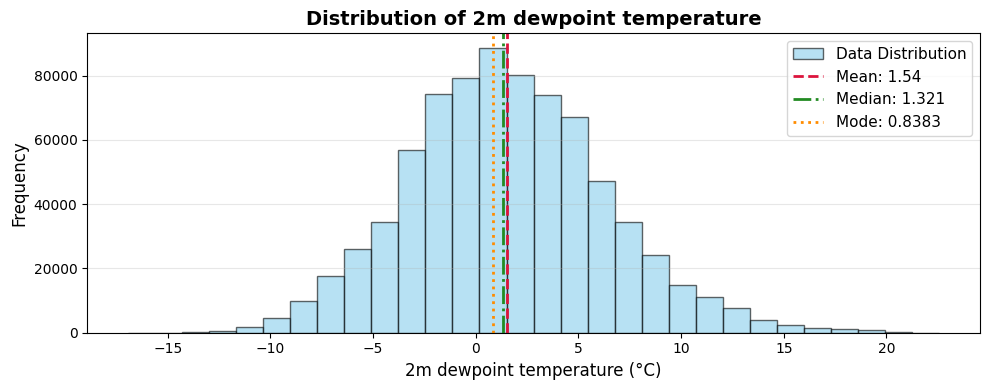

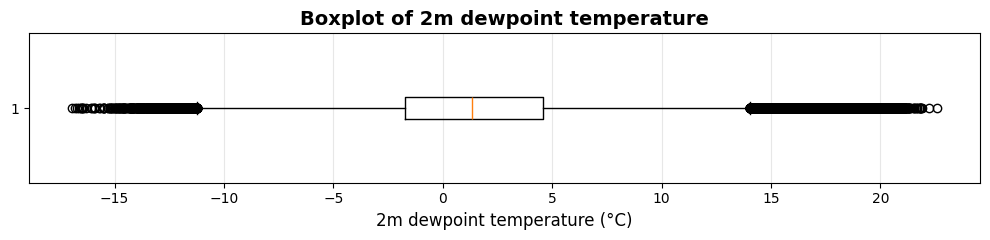

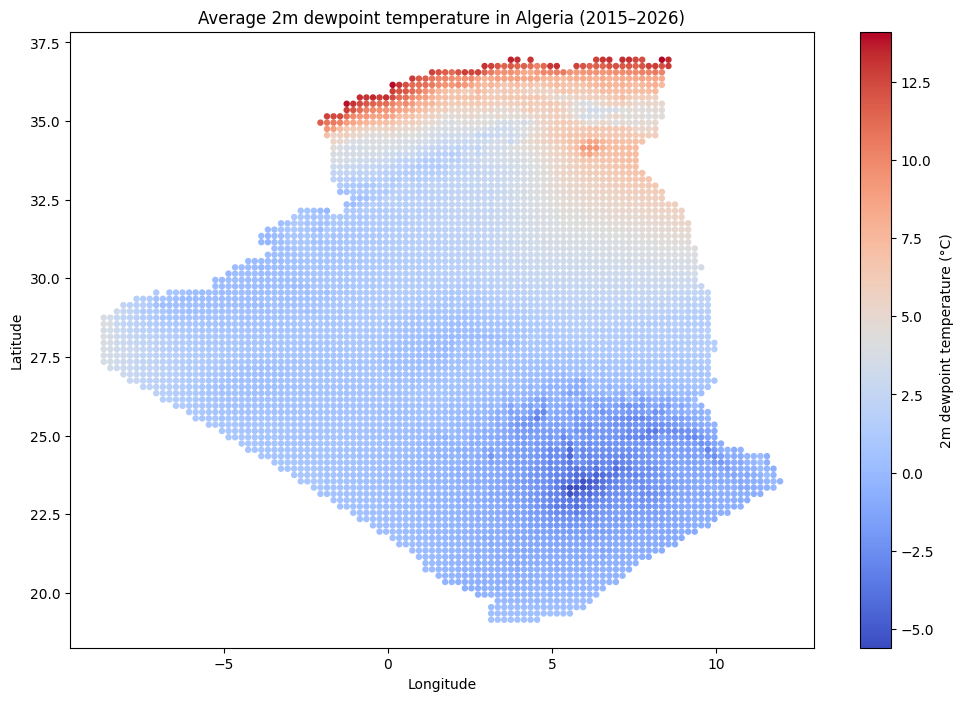

===== 2m temperature (t2m, °C) =====
mean : 23.8946475982666
trimmed mean (10%): 24.068431854248047
midrange: 20.652374267578125
mediane: 24.225250244140625
mode: 33.55801010131836
variance: 76.55830383300781
ecart-type: 8.749760215743505

min: 0.275054931640625  max: 41.029693603515625  range: 40.754638671875
5-number summary: (0.275054931640625, 16.408355712890625, 24.225250244140625, 31.736236572265625, 41.029693603515625)
IQR: 15.327880859375  (bornes outliers : -6.583465576171875 ; 54.728057861328125)
outliers IQR     : 0 (0.00 %)
outliers Z-score : 0 (0.00 %)
mean - mode = -9.66336   |   3 x (mean - median) = -0.991808



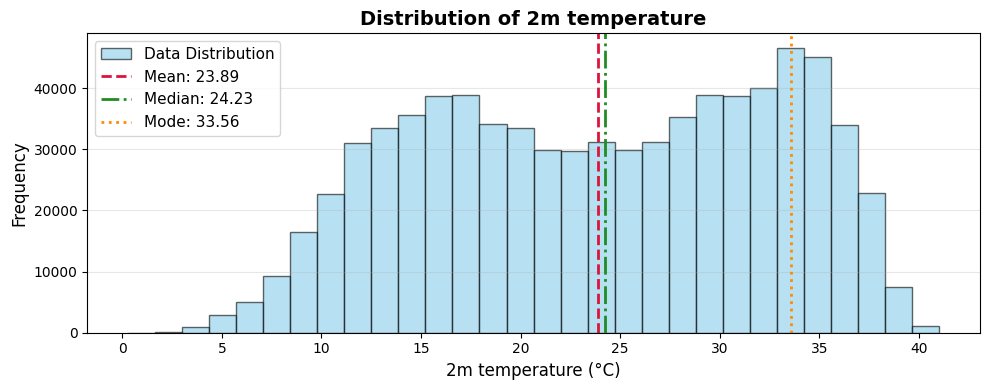

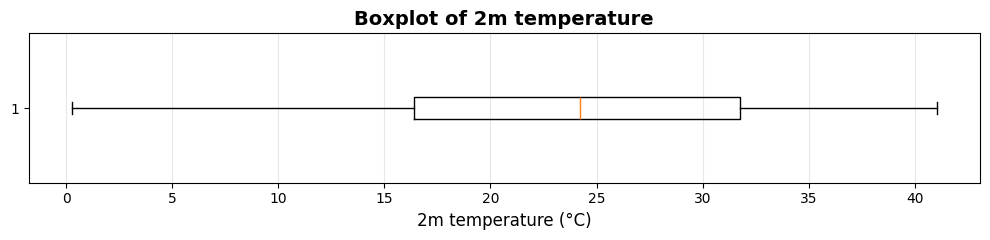

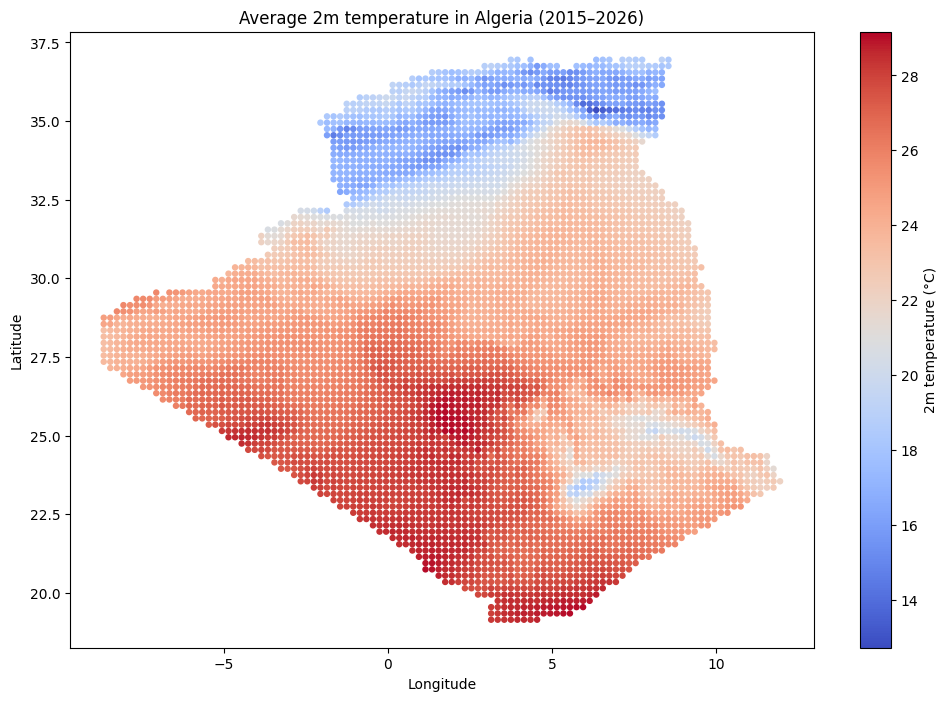

===== Surface latent heat flux (slhf, J/m²) =====
mean : -497845.46875
trimmed mean (10%): -250430.671875
midrange: -5524107.5
mediane: -182114.0
mode: -187624.625
variance: 965686591488.0
ecart-type: 982693.5389469089

min: -11044607.0  max: -3608.25  range: 11040999.0
5-number summary: (-11044607.0, -316589.5, -182114.0, -86614.0, -3608.25)
IQR: 229975.5  (bornes outliers : -661552.75 ; 258349.25)
outliers IQR     : 125680 (16.43 %)
outliers Z-score : 21721 (2.84 %)
mean - mode = -310221   |   3 x (mean - median) = -947194



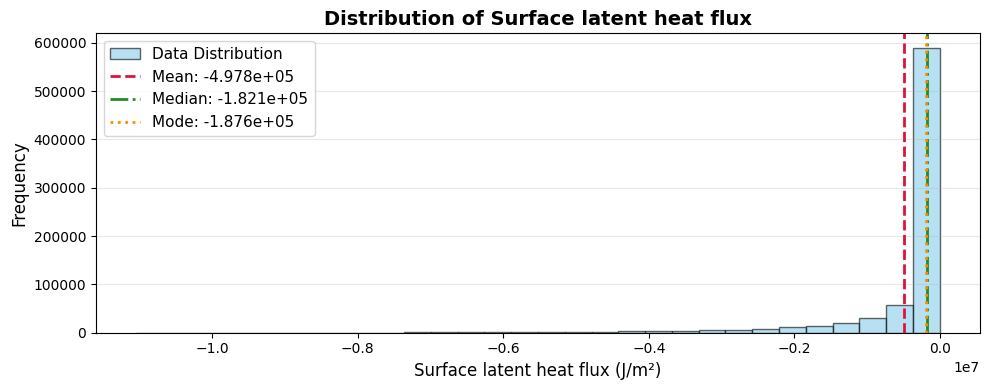

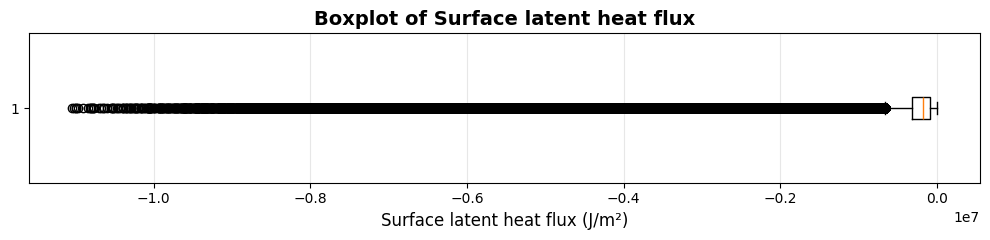

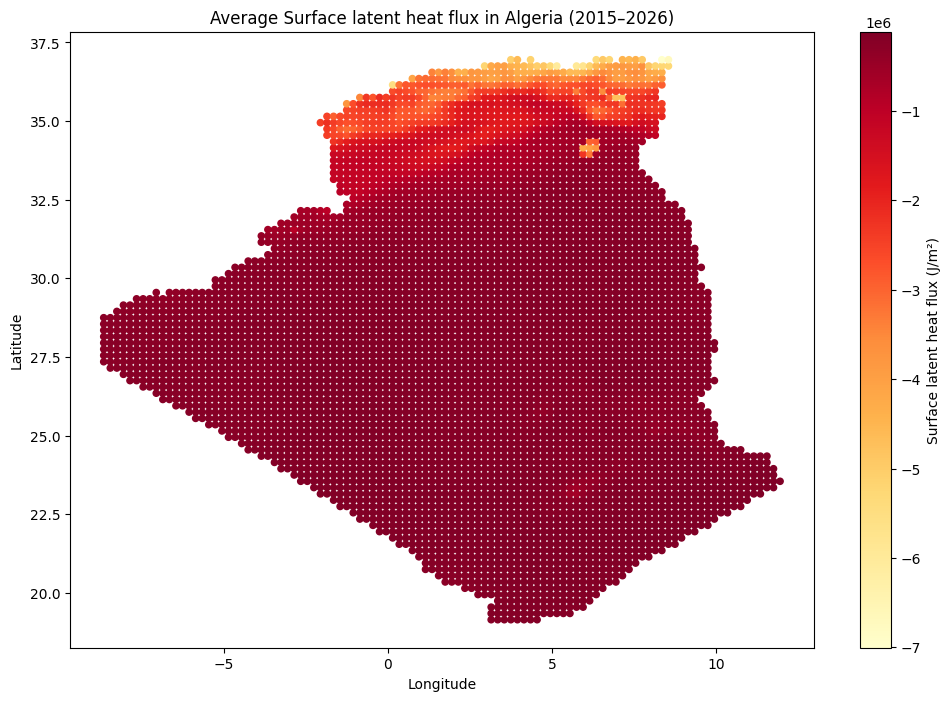

===== Surface net solar radiation (ssr, J/m²) =====
mean : 13510476.0
trimmed mean (10%): 13616997.0
midrange: 14049896.0
mediane: 13974622.0
mode: 16677864.0
variance: 17993931161600.0
ecart-type: 4241925.407359257

min: 2787183.0  max: 25312610.0  range: 22525428.0
5-number summary: (2787183.0, 10140461.25, 13974622.0, 16831059.0, 25312610.0)
IQR: 6690597.75  (bornes outliers : 104564.625 ; 26866955.625)
outliers IQR     : 0 (0.00 %)
outliers Z-score : 0 (0.00 %)
mean - mode = -3.16739e+06   |   3 x (mean - median) = -1.39244e+06



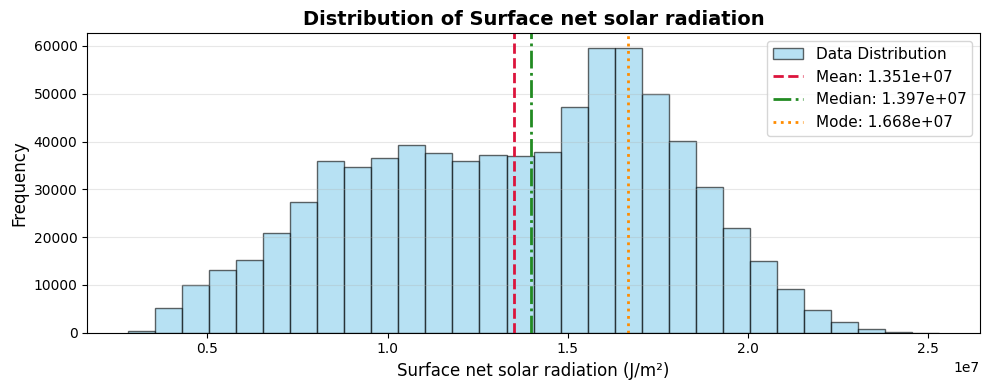

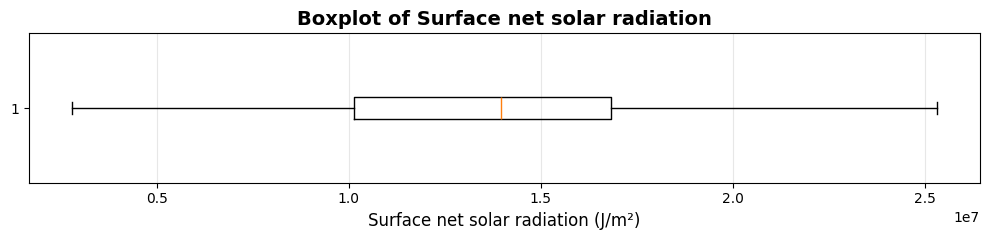

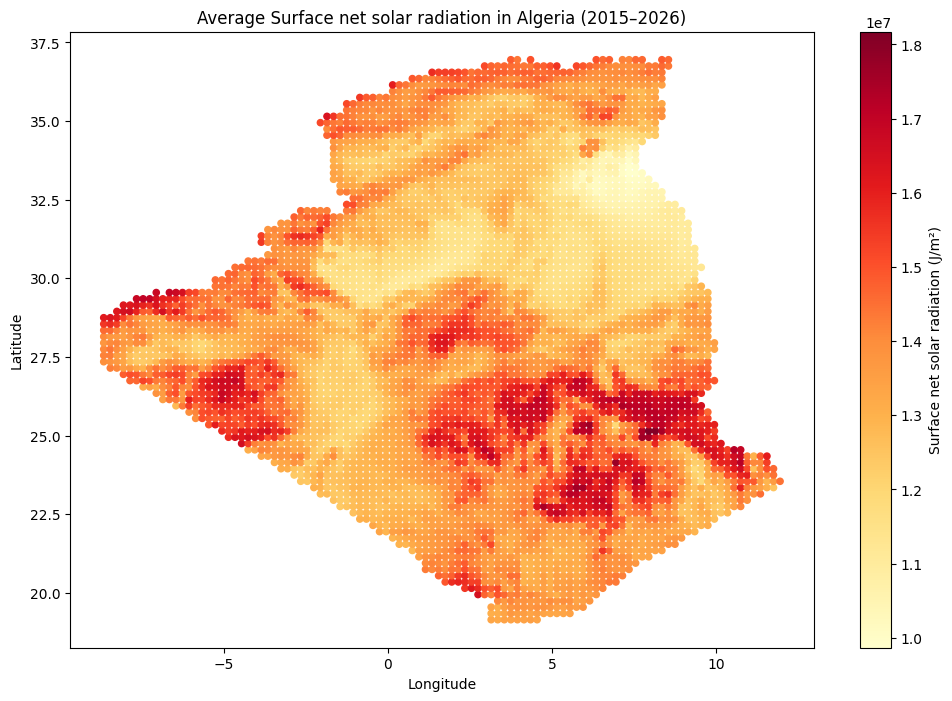

===== Surface net thermal radiation (str, J/m²) =====
mean : -9512614.0
trimmed mean (10%): -9706500.0
midrange: -8567199.0
mediane: -9921715.0
mode: -11781386.0
variance: 6784754909184.0
ecart-type: 2604756.2091650725

min: -14995572.0  max: -2138826.75  range: 12856745.0
5-number summary: (-14995572.0, -11587797.25, -9921715.0, -7960749.5, -2138826.75)
IQR: 3627047.75  (bornes outliers : -17028368.875 ; -2520177.875)
outliers IQR     : 303 (0.04 %)
outliers Z-score : 0 (0.00 %)
mean - mode = 2.26877e+06   |   3 x (mean - median) = 1.2273e+06



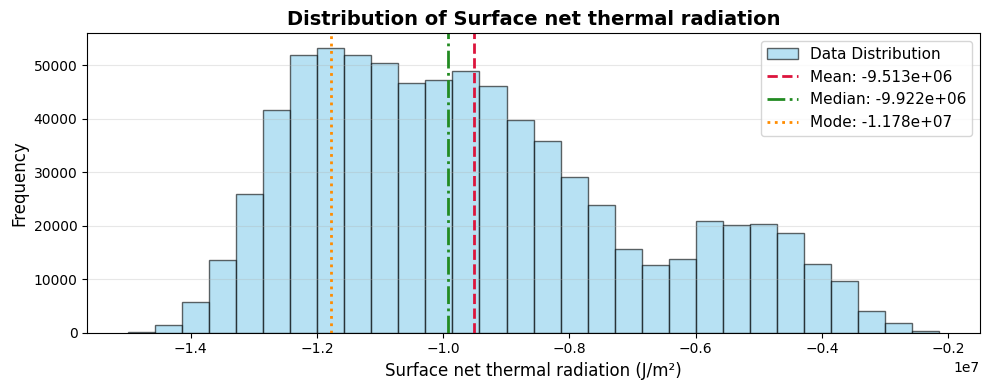

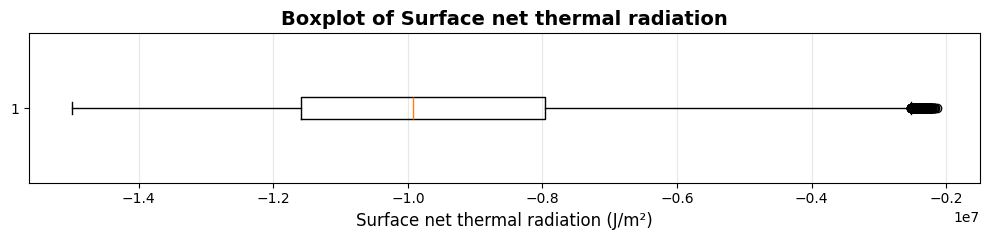

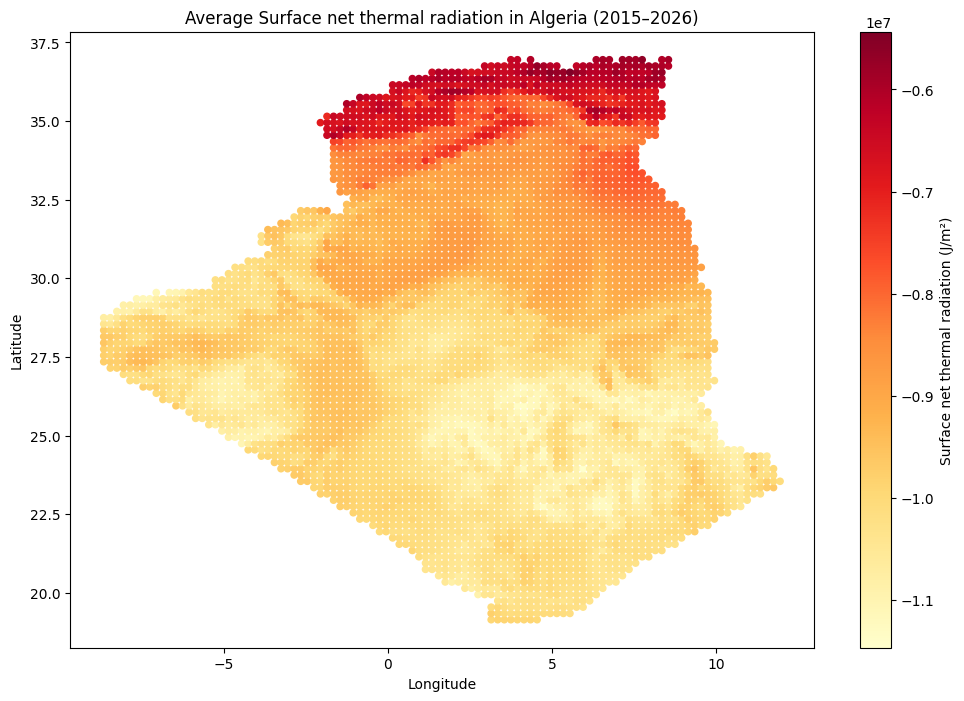

===== Surface sensible heat flux (sshf, J/m²) =====
mean : -3394677.0
trimmed mean (10%): -3310341.0
midrange: -4260781.0
mediane: -3415837.5
mode: -3923332.5
variance: 3732335493120.0
ecart-type: 1931925.3332155463

min: -14384240.0  max: 5862678.0  range: 20246918.0
5-number summary: (-14384240.0, -4651411.125, -3415837.5, -1840956.25, 5862678.0)
IQR: 2810454.875  (bornes outliers : -8867093.4375 ; 2374726.0625)
outliers IQR     : 5865 (0.77 %)
outliers Z-score : 4835 (0.63 %)
mean - mode = 528656   |   3 x (mean - median) = 63481.5



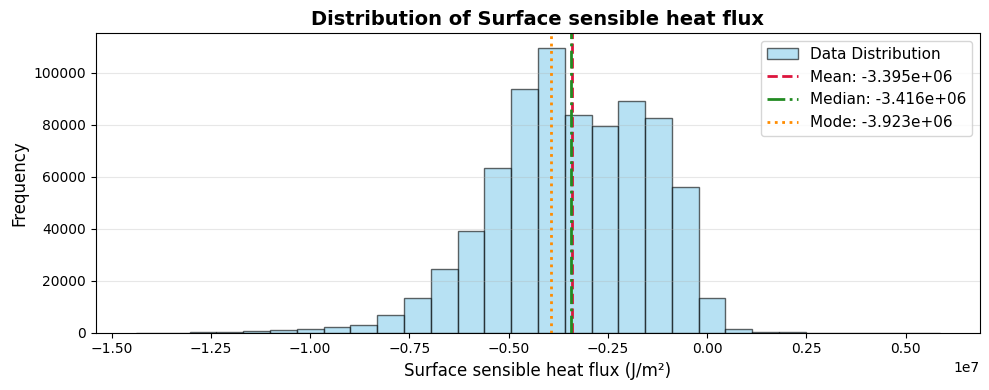

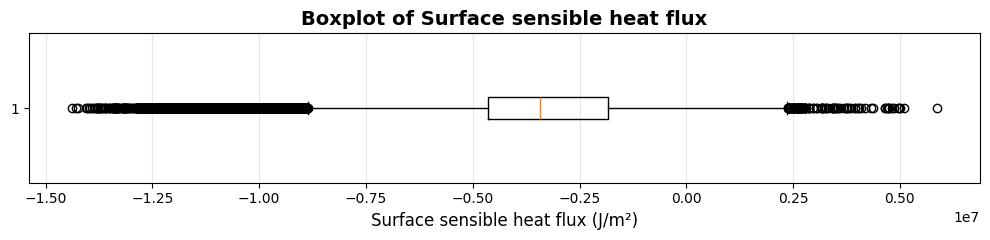

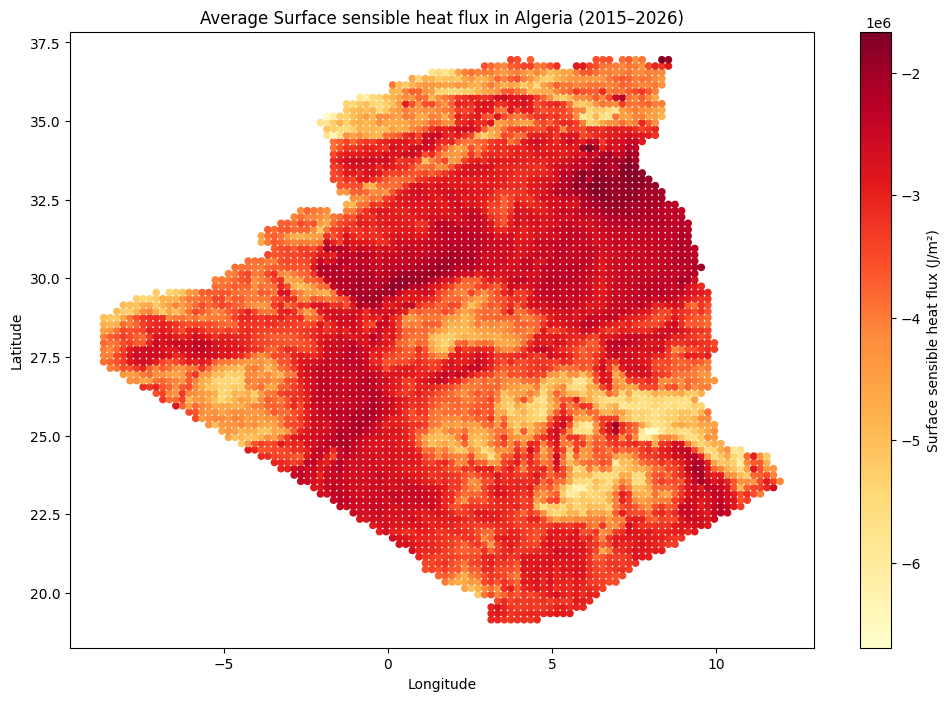

===== Runoff (ro, m) =====
mean : 3.397174168640049e-06
trimmed mean (10%): 2.2386099374216428e-07
midrange: 0.0023975055664777756
mediane: 5.587935447692871e-08
mode: 7.991685561137274e-05
variance: 1.056988940817405e-09
ecart-type: 3.2511366332675174e-05

min: 0.0  max: 0.004795011132955551  range: 0.004795011132955551
5-number summary: (0.0, 5.587935447692871e-09, 5.587935447692871e-08, 3.557652235031128e-07, 0.004795011132955551)
IQR: 3.501772880554199e-07  (bornes outliers : -5.19677996635437e-07 ; 8.810311555862427e-07)
outliers IQR     : 123926 (16.20 %)
outliers Z-score : 5519 (0.72 %)
mean - mode = -7.65197e-05   |   3 x (mean - median) = 1.00239e-05



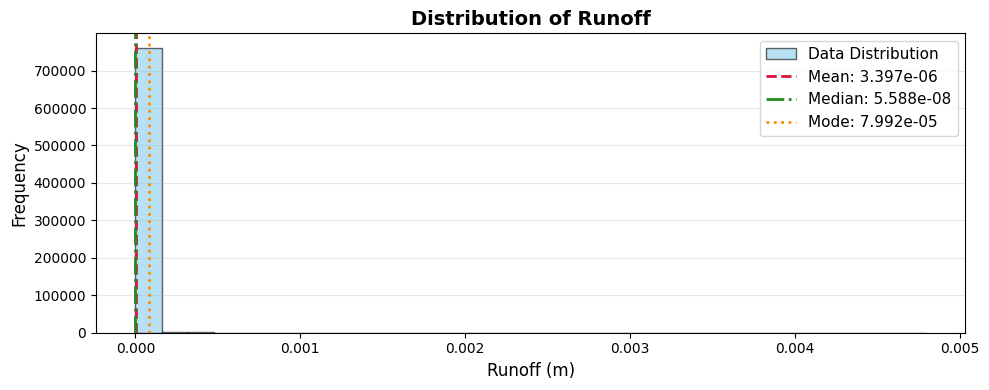

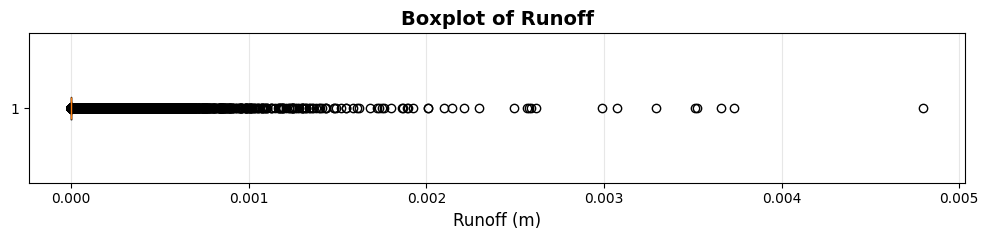

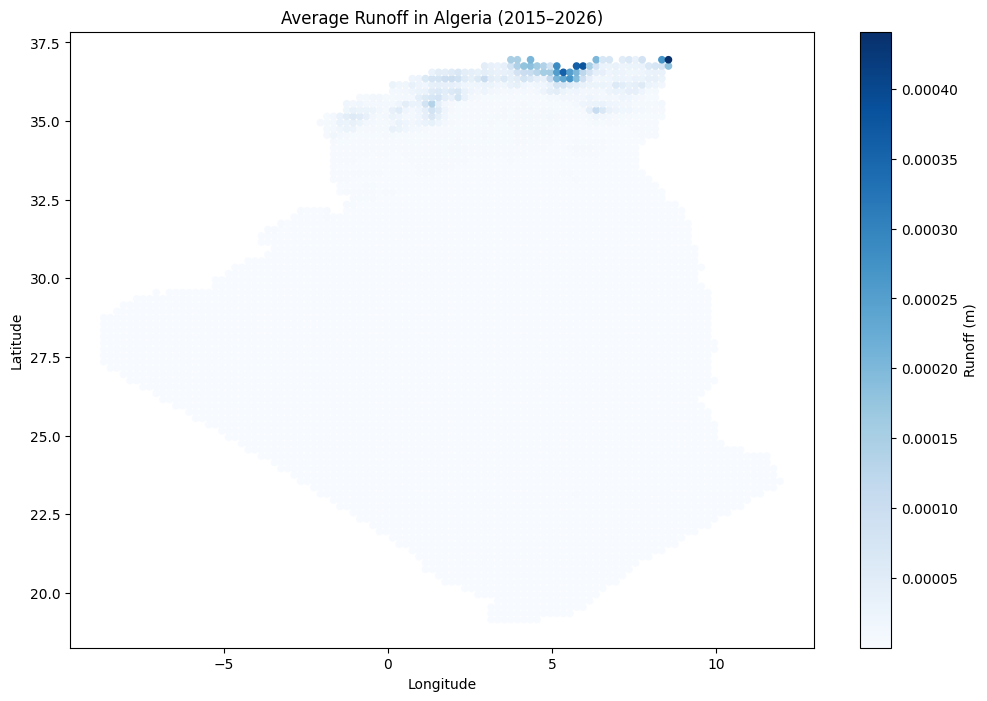

===== Total evaporation (e, m) =====
mean : -0.00019906775560230017
trimmed mean (10%): -0.00010013931023422629
midrange: -0.0022089360281825066
mediane: -7.282209116965532e-05
mode: -7.50258332118392e-05
variance: 1.544033949585355e-07
ecart-type: 0.0003929419740350164

min: -0.004416429437696934  max: -1.44285149872303e-06  range: 0.004414986819028854
5-number summary: (-0.004416429437696934, -0.00012659438652917743, -7.282209116965532e-05, -3.463448956608772e-05, -1.44285149872303e-06)
IQR: 9.19598969630897e-05  (bornes outliers : -0.000264534231973812 ; 0.00010330535587854683)
outliers IQR     : 125681 (16.43 %)
outliers Z-score : 21721 (2.84 %)
mean - mode = -0.000124042   |   3 x (mean - median) = -0.000378737



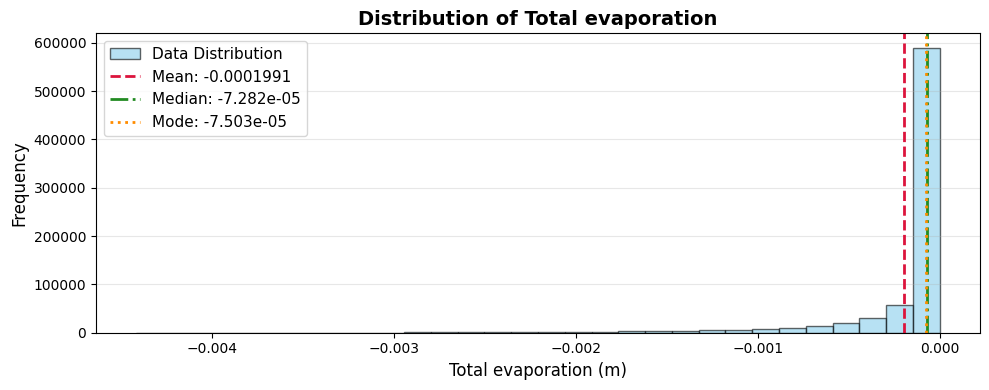

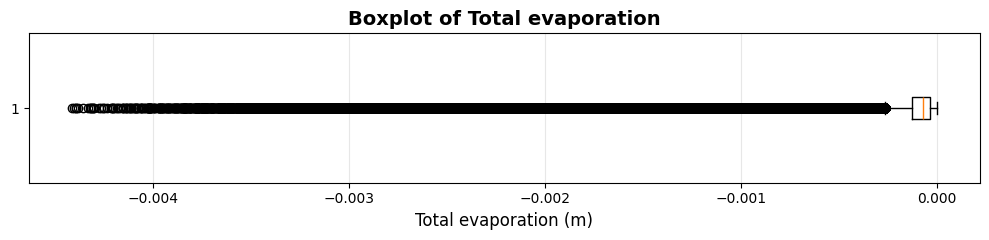

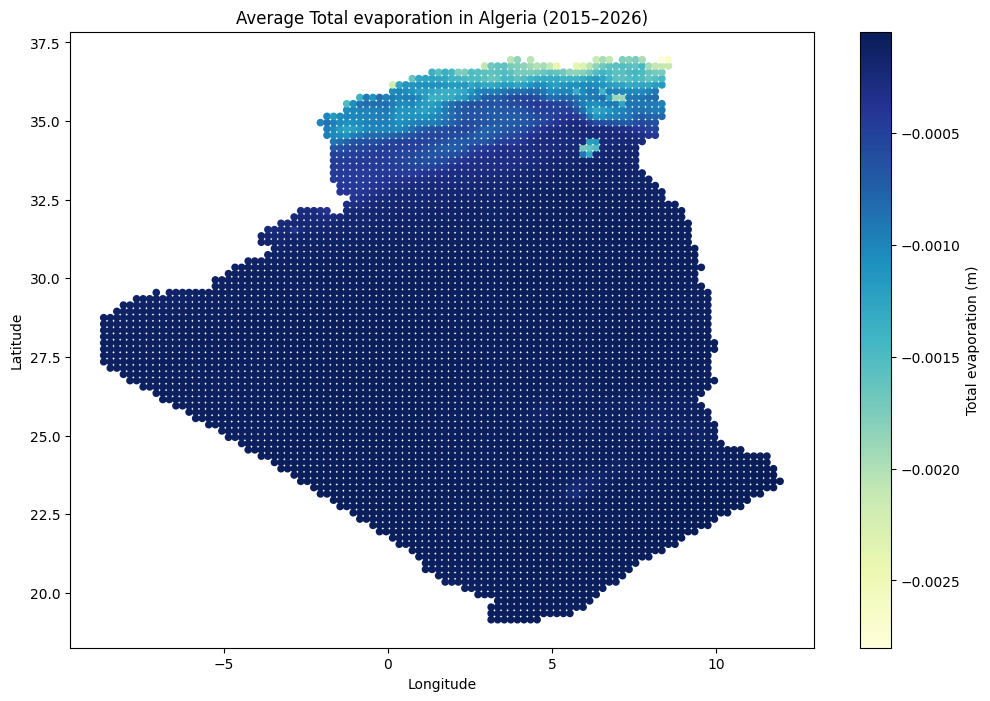

===== 10m u-component of wind (u10, m/s) =====
mean : -1.0252219438552856
trimmed mean (10%): -1.0299346446990967
midrange: 0.3787674903869629
mediane: -0.9951543807983398
mode: -0.8042519092559814
variance: 2.524024724960327
ecart-type: 1.5887179500969728

min: -6.719347953796387  max: 7.4768829345703125  range: 14.1962308883667
5-number summary: (-6.719347953796387, -2.133552312850952, -0.9951543807983398, 0.059530019760131836, 7.4768829345703125)
IQR: 2.193082332611084  (bornes outliers : -5.423175811767578 ; 3.349153518676758)
outliers IQR     : 5546 (0.73 %)
outliers Z-score : 3131 (0.41 %)
mean - mode = -0.22097   |   3 x (mean - median) = -0.0902027



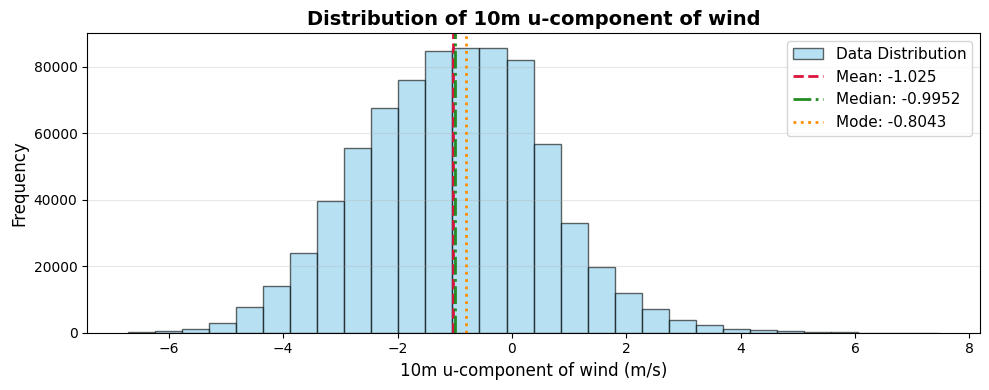

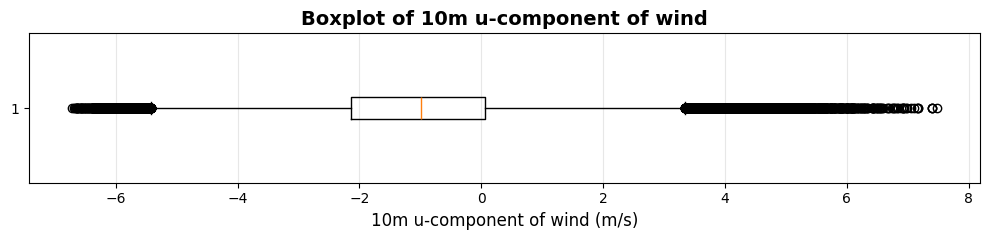

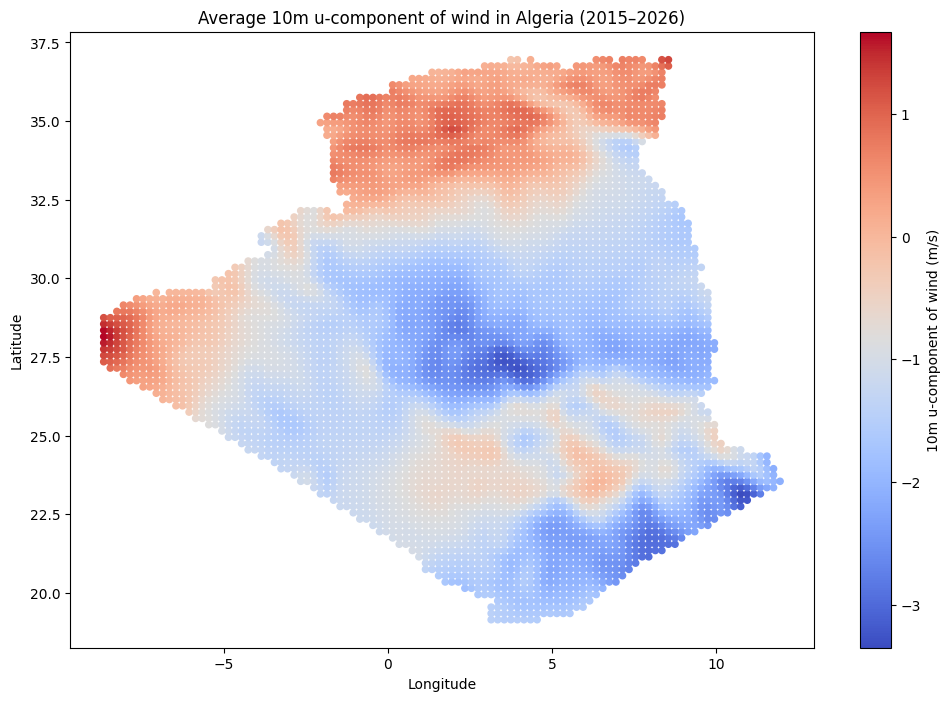

===== 10m v-component of wind (v10, m/s) =====
mean : -0.514147937297821
trimmed mean (10%): -0.4873740077018738
midrange: -0.6801853179931641
mediane: -0.4657268524169922
mode: -0.5470949411392212
variance: 1.0923302173614502
ecart-type: 1.0451460268122585

min: -4.672889709472656  max: 3.312519073486328  range: 7.985408782958984
5-number summary: (-4.672889709472656, -1.1608619689941406, -0.4657268524169922, 0.19645977020263672, 3.312519073486328)
IQR: 1.3573217391967773  (bornes outliers : -3.1968445777893066 ; 2.2324423789978027)
outliers IQR     : 8171 (1.07 %)
outliers Z-score : 1668 (0.22 %)
mean - mode = 0.032947   |   3 x (mean - median) = -0.145263



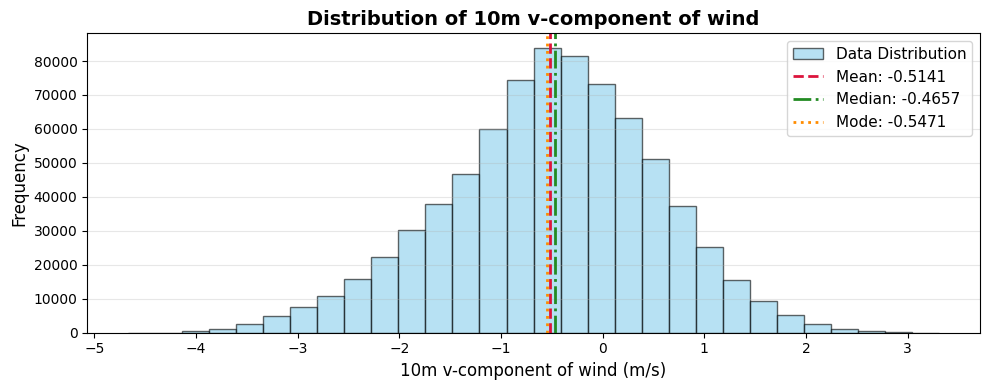

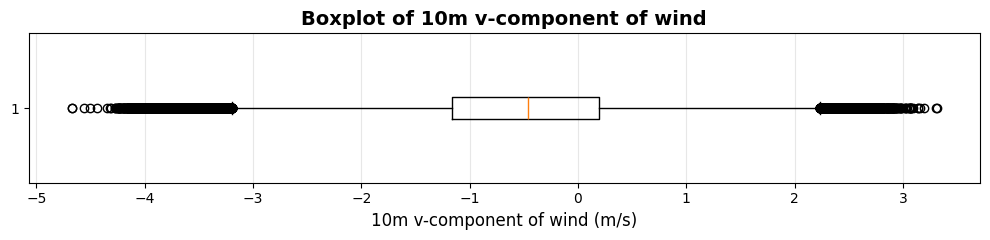

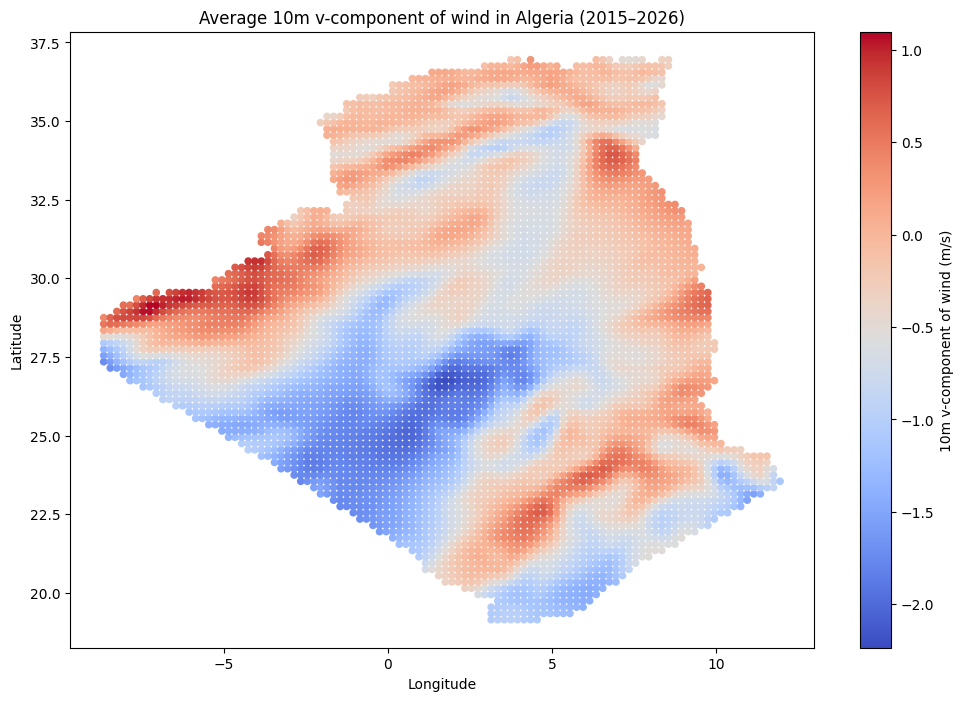

===== Surface pressure (sp, Pa) =====
mean : 95179.2578125
trimmed mean (10%): 95473.40625
midrange: 91710.46875
mediane: 95902.1875
mode: 96846.96875
variance: 11246417.0
ecart-type: 3353.5678016106967

min: 79857.0  max: 103563.9375  range: 23706.9375
5-number summary: (79857.0, 93364.0, 95902.1875, 97561.0, 103563.9375)
IQR: 4197.0  (bornes outliers : 87068.5 ; 103856.5)
outliers IQR     : 13880 (1.81 %)
outliers Z-score : 3757 (0.49 %)
mean - mode = -1667.71   |   3 x (mean - median) = -2168.79



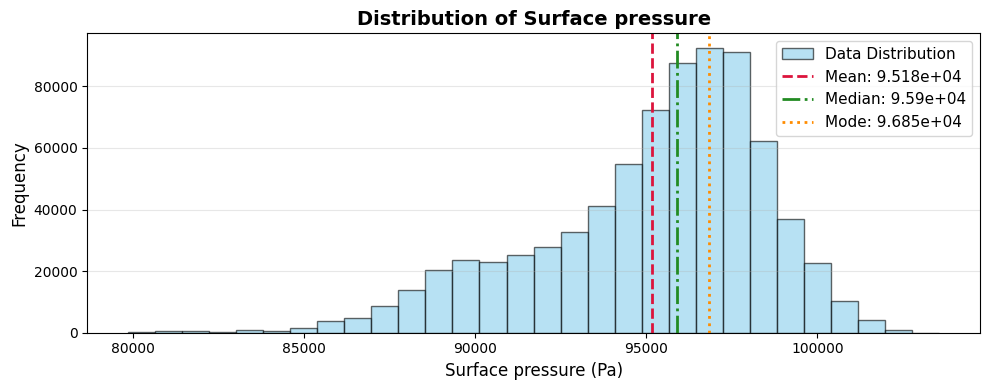

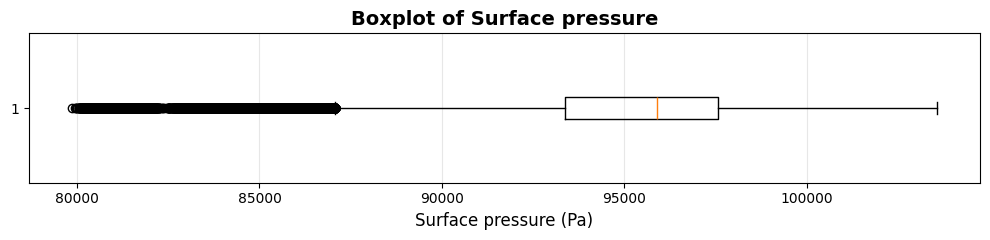

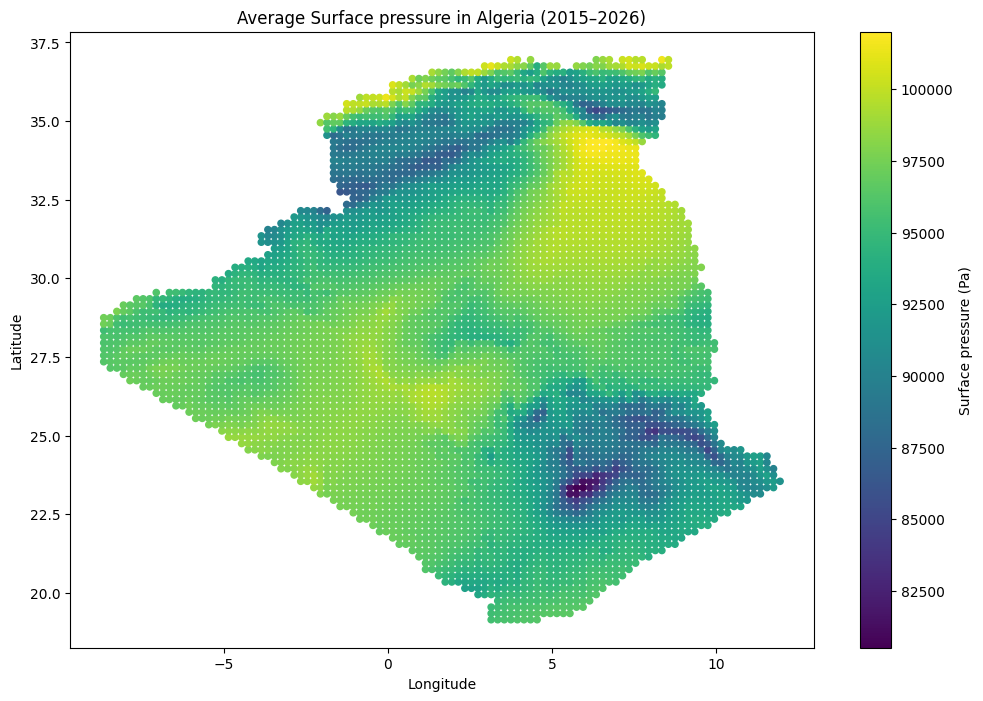

===== Total precipitation (tp, m) =====
mean : 0.00017169657803606242
trimmed mean (10%): 5.824597246828489e-05
midrange: 0.005846272222697735
mediane: 1.8040187569567934e-05
mode: 0.0001951789017766714
variance: 2.2352125483848795e-07
ecart-type: 0.0004727803452328448

min: 3.136232749056944e-07  max: 0.011692230589687824  range: 0.011691916733980179
5-number summary: (3.136232749056944e-07, 2.4953540105343563e-06, 1.8040187569567934e-05, 0.00010021482376032509, 0.011692230589687824)
IQR: 9.771946974979073e-05  (bornes outliers : -0.00014408385061415174 ; 0.0002467940283850112)
outliers IQR     : 115537 (15.11 %)
outliers Z-score : 18325 (2.40 %)
mean - mode = -2.34823e-05   |   3 x (mean - median) = 0.000460969



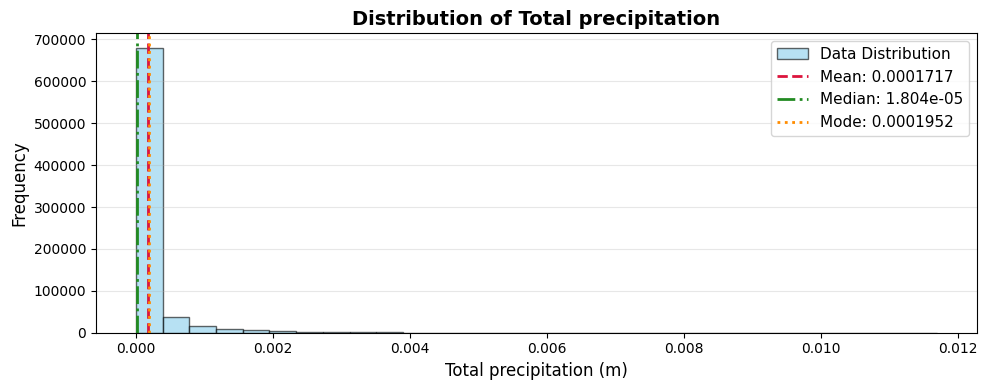

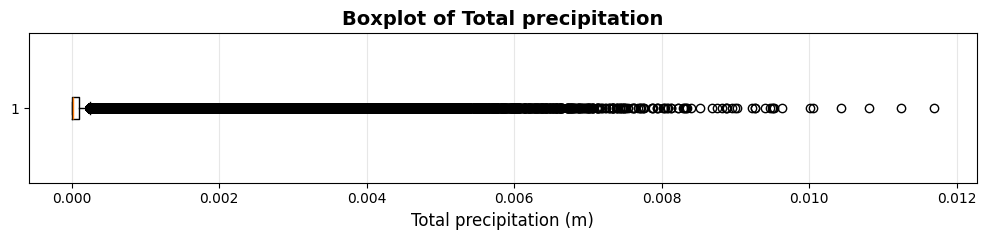

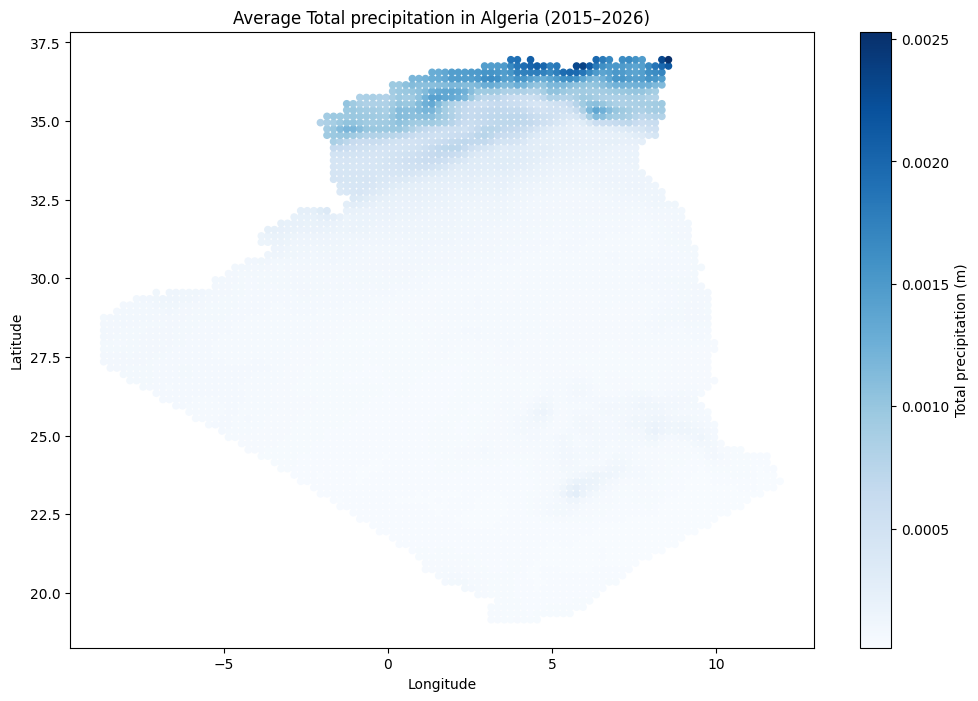

In [18]:
for col, (label, unit, cmap, size) in variables.items():
    df_sorted = df[col].sort_values()
    n = len(df_sorted)          # <-- à ajouter

    mean = df_sorted.mean()
    med = mediane(df_sorted)
    mo = mode(df_sorted)
    variance = df_sorted.var(ddof=0)
    ecart_type = math.sqrt(variance)


    v_min, v_max = df_sorted.min(), df_sorted.max()
    v_range = v_max - v_min
    q1, q3 = df_sorted.quantile([0.25, 0.75])
    iqr = q3 - q1
    # AJOUT : moyenne tronquée (10 % retirés de chaque côté) et midrange
    k = int(0.1 * n)
    trimmed_mean = df_sorted.iloc[k:n - k].mean()     # df_sorted est déjà trié
    midrange = (v_min + v_max) / 2


    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out_iqr = ((df_sorted < low) | (df_sorted > high)).sum()
    z = (df_sorted - mean) / ecart_type
    out_z = (z.abs() > 3).sum()

    print(f"===== {label} ({col}, {unit}) =====")
    print(f"mean : {mean}")
    print(f"trimmed mean (10%): {trimmed_mean}")
    print(f"midrange: {midrange}")
    print(f"mediane: {med}")
    print(f"mode: {mo}")
    print(f"variance: {variance}")
    print(f"ecart-type: {ecart_type}\n")
    print(f"min: {v_min}  max: {v_max}  range: {v_range}")
    print(f"5-number summary: ({v_min}, {q1}, {med}, {q3}, {v_max})")
    print(f"IQR: {iqr}  (bornes outliers : {low} ; {high})")
    print(f"outliers IQR     : {out_iqr} ({100*out_iqr/n:.2f} %)")
    print(f"outliers Z-score : {out_z} ({100*out_z/n:.2f} %)")
    print(f"mean - mode = {mean - mo:.6g}   |   3 x (mean - median) = {3*(mean - med):.6g}\n")

    # distribution
    plt.figure(figsize=(10, 4))
    plt.hist(df_sorted, bins=30, alpha=0.6, color='skyblue', edgecolor='black', label='Data Distribution')
    plt.axvline(mean, color='crimson', linestyle='--', linewidth=2, label=f'Mean: {mean:.4g}')
    plt.axvline(med, color='forestgreen', linestyle='-.', linewidth=2, label=f'Median: {med:.4g}')
    plt.axvline(mo, color='darkorange', linestyle=':', linewidth=2, label=f'Mode: {mo:.4g}')
    plt.title(f'Distribution of {label}', fontsize=14, fontweight='bold')
    plt.xlabel(f'{label} ({unit})', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.legend(fontsize=11)
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

    # AJOUT : boxplot
    plt.figure(figsize=(10, 2.5))
    plt.boxplot(df_sorted, vert=False)
    plt.title(f'Boxplot of {label}', fontsize=14, fontweight='bold')
    plt.xlabel(f'{label} ({unit})', fontsize=12)
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

    # carte des moyennes par point de grille
    mean_map = df.groupby(['latitude', 'longitude'])[col].mean().reset_index()
    fig, ax = plt.subplots(figsize=(12, 8))
    sc = ax.scatter(mean_map['longitude'], mean_map['latitude'],
                    c=mean_map[col], cmap=cmap, s=size)
    plt.colorbar(sc, ax=ax, label=f'{label} ({unit})')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_title(f'Average {label} in Algeria (2015–2026)')
    plt.show()

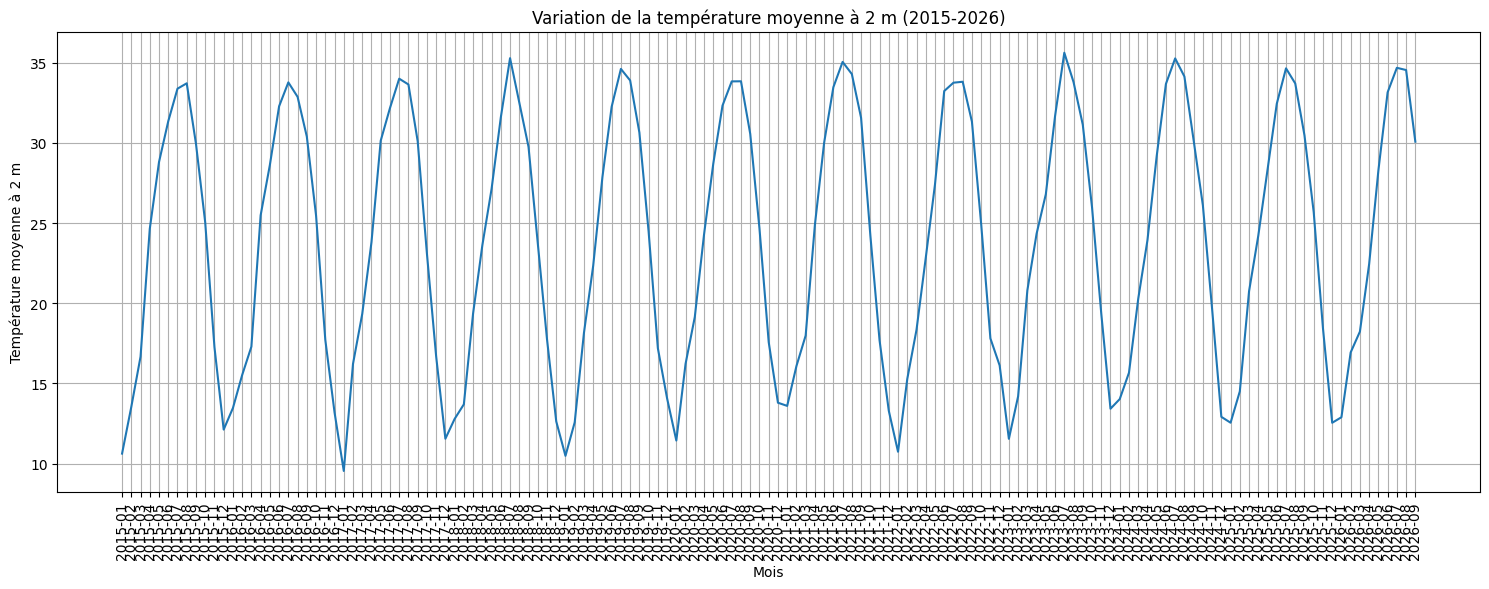

In [17]:
import pandas as pd
#variation de la temperature moyenne a 2m chaque mois entre 2015 et 2026
df['valid_time'] = pd.to_datetime(df['valid_time'])
monthly_temp = df.groupby(
    df['valid_time'].dt.to_period('M')
)['t2m'].mean()

plt.figure(figsize=(15, 6))

plt.plot(monthly_temp.index.astype(str), monthly_temp.values)

plt.title("Variation de la température moyenne à 2 m (2015-2026)")
plt.xlabel("Mois")
plt.ylabel("Température moyenne à 2 m")
plt.xticks(rotation=90)
plt.grid(True)

plt.tight_layout()
plt.show()

# multivariate analysis

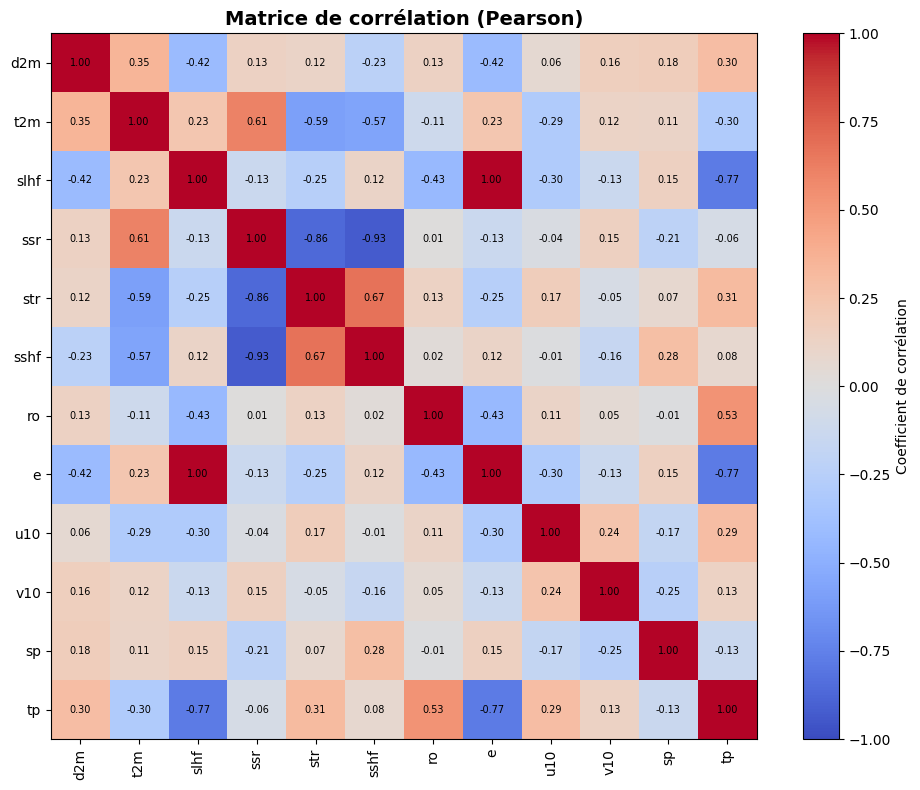

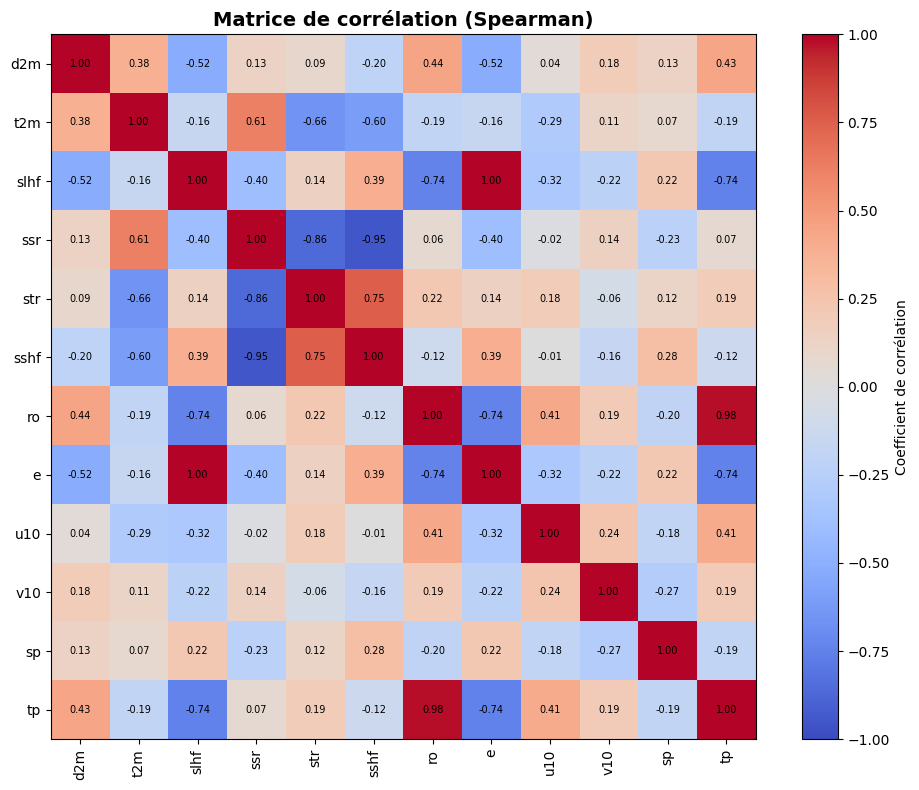

Corrélation avec t2m (Pearson) :
ssr     0.608291
str    -0.591589
sshf   -0.565172
d2m     0.345046
tp     -0.295902
u10    -0.289284
slhf    0.229085
e       0.229052
v10     0.119568
sp      0.111526
ro     -0.109423
Name: t2m, dtype: float64

Corrélation avec t2m (Spearman) :
str    -0.655634
ssr     0.612527
sshf   -0.603027
d2m     0.377303
u10    -0.290773
ro     -0.189098
tp     -0.186552
e      -0.161718
slhf   -0.161712
v10     0.109784
sp      0.070886
Name: t2m, dtype: float64


In [19]:
import numpy as np
import pandas as pd

features = ['d2m', 't2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']

pearson = df[features].corr(method='pearson')
spearman = df[features].corr(method='spearman')

def heatmap(c, title):
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(c, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(c))); ax.set_xticklabels(c.columns, rotation=90)
    ax.set_yticks(range(len(c))); ax.set_yticklabels(c.columns)
    for i in range(len(c)):
        for j in range(len(c)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha='center', va='center', fontsize=7)
    plt.colorbar(im, label='Coefficient de corrélation')
    ax.set_title(title, fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()

heatmap(pearson, 'Matrice de corrélation (Pearson)')
heatmap(spearman, 'Matrice de corrélation (Spearman)')

print("Corrélation avec t2m (Pearson) :")
print(pearson['t2m'].drop('t2m').sort_values(key=abs, ascending=False))
print("\nCorrélation avec t2m (Spearman) :")
print(spearman['t2m'].drop('t2m').sort_values(key=abs, ascending=False))

Variance expliquée : [0.308 0.265 0.119 0.089 0.064 0.06  0.041 0.023 0.018 0.014 0.    0.   ]
Cumulée            : [0.308 0.572 0.692 0.78  0.844 0.904 0.945 0.969 0.986 1.    1.    1.   ]


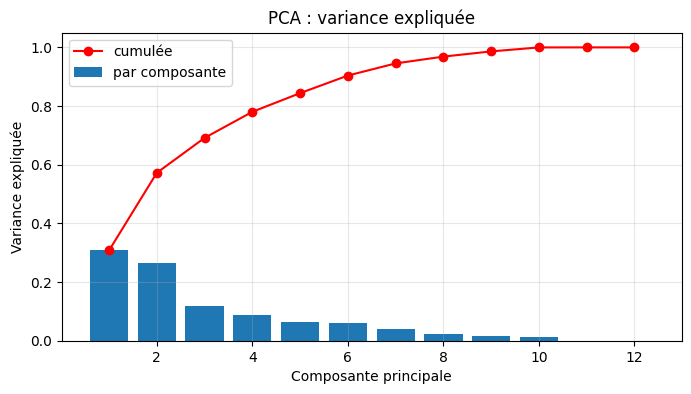

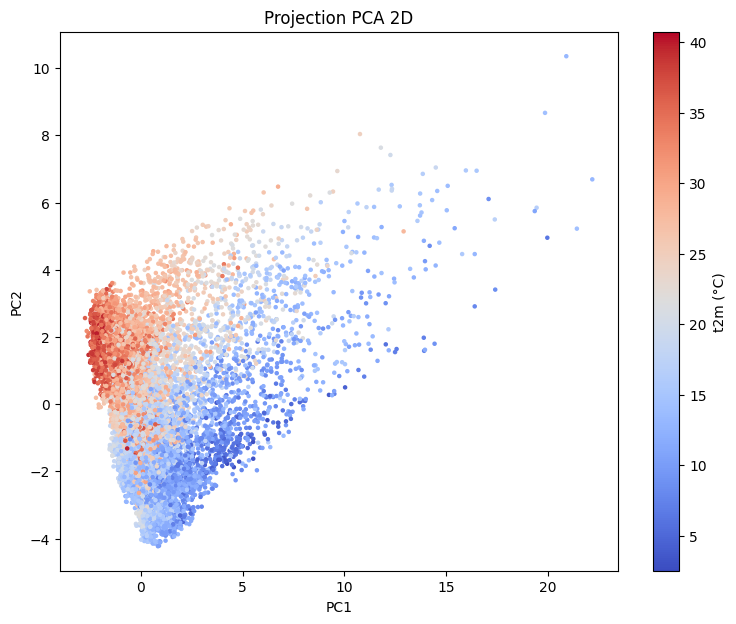

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sample = df.sample(20000, random_state=0)
X = StandardScaler().fit_transform(sample[features])     # standardisation obligatoire

pca = PCA(n_components=len(features)).fit(X)
ratio = pca.explained_variance_ratio_
print("Variance expliquée :", ratio.round(3))
print("Cumulée            :", ratio.cumsum().round(3))

plt.figure(figsize=(8, 4))
plt.bar(range(1, len(ratio) + 1), ratio, label='par composante')
plt.plot(range(1, len(ratio) + 1), ratio.cumsum(), 'ro-', label='cumulée')
plt.xlabel('Composante principale'); plt.ylabel('Variance expliquée')
plt.title('PCA : variance expliquée'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

X2 = PCA(n_components=2).fit_transform(X)
plt.figure(figsize=(9, 7))
sc = plt.scatter(X2[:, 0], X2[:, 1], c=sample['t2m'], cmap='coolwarm', s=5)
plt.colorbar(sc, label='t2m (°C)')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Projection PCA 2D')
plt.show()

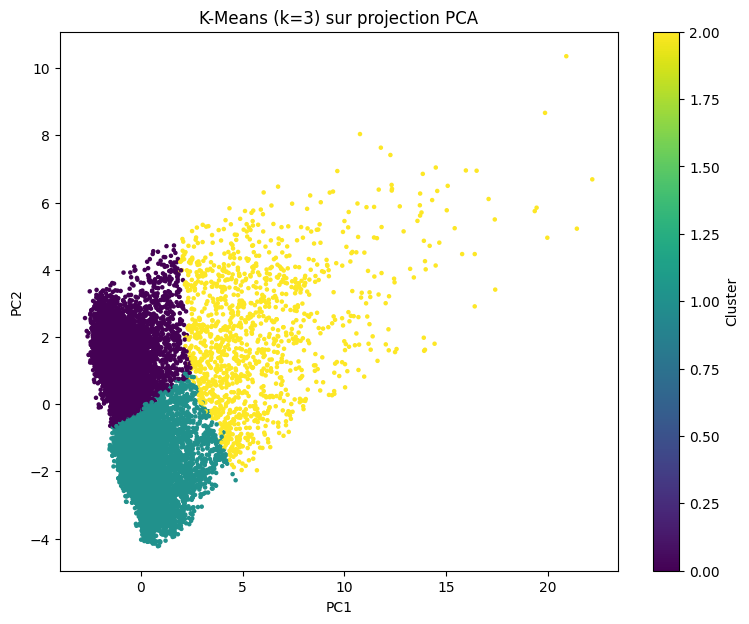

In [21]:
from sklearn.cluster import KMeans

labels = KMeans(n_clusters=3, random_state=0, n_init=10).fit_predict(X)

plt.figure(figsize=(9, 7))
sc = plt.scatter(X2[:, 0], X2[:, 1], c=labels, cmap='viridis', s=5)
plt.colorbar(sc, label='Cluster')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('K-Means (k=3) sur projection PCA')
plt.show()